# Proyección de la TPM: modelos, evaluación fuera de muestra y escenarios

**Qué hace este notebook**, paso a paso:

1. Prepara el entorno e importa las funciones del proyecto.
2. Define la jerarquía de modelos y benchmarks.
3. Revisa los datos: faltantes, información disponible en cada mes y panel de modelación.
4. Estima un modelo univariado (ARIMA).
5. Estima la regla de Taylor con inferencia robusta (HAC).
6. Evalúa los pronósticos fuera de muestra, sin sesgo de anticipación.
7. Proyecta la TPM a 24 meses con escenarios de riesgo.
8. Resume conclusiones y limitaciones.

Todas las cifras se calculan aquí con los datos de `data/base.db` (fecha de corte: 30 de septiembre de 2026). Las funciones viven en `modelos/datos_modelo.py` y en la carpeta `tpm/`; este notebook solo las llama y las interpreta.

## 0. Preparación del entorno

El notebook está en `notebooks/`, así que agregamos la carpeta raíz del proyecto a `sys.path` para poder importar `modelos` y `tpm`. Con `autoreload`, si se edita un archivo `.py`, el notebook usa la versión nueva sin reiniciar el kernel.

In [31]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import norm
from statsmodels.stats.stattools import durbin_watson

RAIZ = Path.cwd().parent          # el notebook vive en notebooks/
if str(RAIZ) not in sys.path:
    sys.path.append(str(RAIZ))

%load_ext autoreload
%autoreload 2

from modelos.datos_modelo import (leer_consultas, armar_panel, brecha_ex_post,
                                  brecha_tiempo_real, REZAGO_PUBLICACION)
from tpm import arima, taylor, evaluacion, proyeccion
from tpm.metricas import tabla_metricas, BENCHMARK

pd.set_option("display.float_format", "{:.3f}".format)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [32]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Cada modelo tiene siempre el mismo color, en todos los gráficos
COLORES = {
    "TPM efectiva": "#191919",
    "Regla de Taylor": "#257de0",
    "ARIMA": "#f47230",
    BENCHMARK: "#9c9c9c",
    "Convergencia": "#00b894",
    "Riesgo al alza": "#f2a600",
    "Riesgo a la baja": "#ee7fac",
    "Brecha ex post": "#6a4ce2",
    "Brecha en tiempo real": "#ec4647",
}
TINTA = "#191919"
TINTA_SECUNDARIA = "#666666"
FUENTE = "Fuente: BCCh y FRED, base del proyecto (corte 30-sep-2026)."

plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c2c2c2", "axes.labelcolor": TINTA_SECUNDARIA,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e7e7e7", "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": TINTA_SECUNDARIA, "ytick.color": TINTA_SECUNDARIA,
    "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 9,
})


def nota_fuente(fig, texto=FUENTE, y=-0.02):
    """Agrega la fuente al pie de la figura (y más negativo = más abajo)."""
    fig.text(0.01, y, texto, fontsize=8, color=TINTA_SECUNDARIA)

## 1. Modelos y jerarquía de benchmarks

Un modelo de pronóstico solo tiene valor si le gana a alternativas más simples. Seguimos la jerarquía de benchmarks vista en clases (*Benchmarks econométricos y modelos anidados*):

| Nivel | Modelo | Pregunta que responde |
|---|---|---|
| 1. Benchmark ingenuo | **Caminata aleatoria**: $\hat{TPM}_{t+h} = TPM_t$ | ¿El modelo supera a "la tasa se mantiene"? |
| 2. Benchmark univariado | **ARIMA**: la TPM explicada solo por su propia historia | ¿Las variables económicas agregan algo que no esté ya en la historia de la TPM? |
| 3. Modelo económico | **Regla de Taylor** con inercia | ¿La respuesta del Banco Central a la inflación esperada, la actividad y la tasa externa mejora el pronóstico? |

La caminata aleatoria está **anidada** en la regla de Taylor: es el caso particular con $\rho = 1$ y el resto de los coeficientes en cero. Por eso, para saber si la regla mejora significativamente al benchmark, usaremos el test de Clark y West (2007), diseñado para modelos anidados.

## 2. Datos y preprocesamiento

Los datos vienen del pipeline del proyecto: **API (BCCh y FRED) → SQLite → consultas SQL → Python**. Tres decisiones de preprocesamiento, siguiendo la clase de *Pre-procesamiento y análisis exploratorio*:

- **De diario a mensual:** la TPM se mide como **valor de fin de mes** (cierre) y no como promedio, porque cambia en fechas puntuales: el promedio de un mes con reunión daría una tasa que nunca estuvo vigente. Las tasas de bonos sí se promedian.
- **Faltantes:** se guardan como `NULL` y **no se imputan**. Interpolar usaría el dato siguiente, lo que introduce sesgo de anticipación en un pronóstico.
- **Transformaciones:** las variaciones en 12 meses se calculan en SQL con funciones de ventana (`LAG`, `SUM … OVER`) y no se recalculan en Python.

### 2.1 Diagnóstico de faltantes

Solo cuentan como faltantes los meses vacíos **dentro** del período de cada serie: antes de su primer dato la serie todavía no existía.

In [33]:
niveles, var12 = leer_consultas()

def diagnostico_faltantes(tabla: pd.DataFrame) -> pd.DataFrame:
    # Una fila por serie: período, meses y cuáles meses están vacíos
    filas = []
    for nombre, serie in tabla.items():
        tramo = serie.loc[serie.first_valid_index():serie.last_valid_index()]
        vacios = tramo[tramo.isna()].index
        filas.append({"serie": nombre, "inicio": f"{tramo.index.min():%Y-%m}",
                      "fin": f"{tramo.index.max():%Y-%m}", "meses": len(tramo),
                      "faltantes": len(vacios),
                      "meses_faltantes": ", ".join(vacios.strftime("%Y-%m"))})
    return pd.DataFrame(filas).set_index("serie")

diagnostico_faltantes(niveles)

,inicio,fin,meses,faltantes,meses_faltantes
serie,,,,,
desempleo,2010-03,2026-09,199,0,
dolar_observado,2000-01,2026-09,321,0,
expectativa_ipc_eee,2001-01,2026-09,309,7,"2001-02, 2001-03, 2001-04, 2001-05, 2001-06, 2..."
fed_funds,2000-01,2026-09,321,0,
imacec,2000-01,2026-09,321,0,
ipc,2000-01,2026-09,321,0,
ipc_eeuu,2000-01,2026-09,321,1,2025-10
ipc_sae,2010-01,2026-09,201,0,
precio_cobre,2000-01,2026-09,321,0,


**Lectura:** hay 8 meses faltantes en total: la expectativa de inflación (EEE) de febrero a agosto de 2001, los primeros meses de la encuesta, y el IPC de EE.UU. de octubre de 2025. Ninguno afecta a los modelos: el panel de modelación parte en 2005 (sección 2.4) y el IPC de EE.UU. no entra en ninguna regla.

### 2.2 Información disponible en cada mes: rezagos de publicación

La regla de oro del pronóstico es la **separación temporal estricta**: en cada fecha solo se puede usar información que ya estaba publicada. Si no, aparece el **sesgo de anticipación** (*look-ahead bias*) y el pronóstico parece mejor de lo que es.

Por eso cada fila $t$ del panel contiene solo lo que se sabía al **cierre del mes $t-1$**. Cada serie entra rezagada según su calendario de publicación:

In [34]:
pd.Series(REZAGO_PUBLICACION, name="rezago_meses").to_frame()

,rezago_meses
tpm,1
expectativa_ipc_eee,1
fed_funds,1
dolar_observado,1
ipc,2
ipc_sae,2
desempleo,2
precio_cobre,2
imacec,3


Por ejemplo, para pronosticar la TPM de octubre, al 30 de septiembre se conoce la EEE de septiembre (rezago 1), pero solo el IPC de agosto (rezago 2) y el Imacec de julio (rezago 3).

### 2.3 Brecha de actividad: ex post frente a tiempo real

La brecha de actividad es la desviación porcentual del Imacec desestacionalizado respecto de su tendencia, estimada con el filtro de Hodrick-Prescott ($\lambda = 14.400$ para datos mensuales).

- **Brecha ex post:** el filtro se aplica a toda la muestra (filtro de dos colas). La tendencia de 2015 usa datos de 2016 en adelante, así que **solo sirve para describir el pasado**.
- **Brecha en tiempo real:** para cada mes se toma el Imacec conocido hasta ese momento, se desestacionaliza y se filtra (filtro de una cola). Es la que habría calculado un analista en esa fecha, y **es la que usan los modelos**.

In [35]:
brechas = pd.concat({"ex_post": brecha_ex_post(niveles["imacec"]),
                     "tiempo_real": brecha_tiempo_real(niveles["imacec"])}, axis=1).dropna()

print(f"Correlación entre ambas brechas: {brechas.corr().iloc[0, 1]:.2f}")
brechas.tail(6)

Correlación entre ambas brechas: 0.71


,ex_post,tiempo_real
2026-04-01,-0.542,-1.504
2026-05-01,-2.310,-2.936
2026-06-01,-0.581,-1.088
2026-07-01,-1.458,-1.760
2026-08-01,-2.909,-2.846
2026-09-01,0.512,0.512


Las dos medidas se parecen (correlación de 0,71), pero no son iguales, sobre todo en los últimos meses, donde el filtro ex post todavía no tiene datos posteriores.

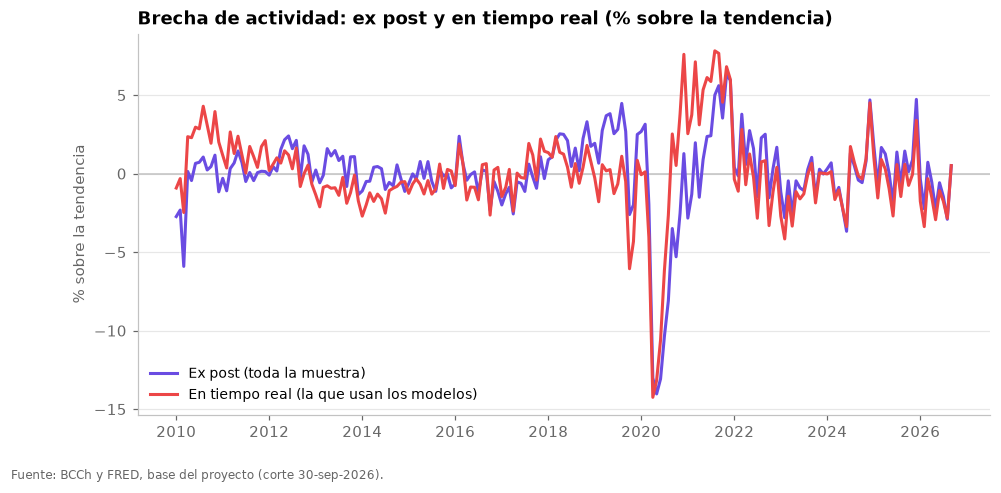

In [36]:
datos = brechas.loc["2010-01-01":]
fig, ax = plt.subplots()
ax.axhline(0, color="#c2c2c2", lw=1)
ax.plot(datos.index, datos["ex_post"], color=COLORES["Brecha ex post"], label="Ex post (toda la muestra)")
ax.plot(datos.index, datos["tiempo_real"], color=COLORES["Brecha en tiempo real"],
        label="En tiempo real (la que usan los modelos)")
ax.set_title("Brecha de actividad: ex post y en tiempo real (% sobre la tendencia)")
ax.set_ylabel("% sobre la tendencia")
ax.legend(loc="lower left")
nota_fuente(fig)
plt.show()

### 2.4 Panel de modelación

`armar_panel()` junta la TPM y sus determinantes ya rezagados y elimina las filas incompletas.

In [37]:
panel_completo = armar_panel(eliminar_faltantes=False)
panel = armar_panel()

print(f"Antes de eliminar faltantes: {panel_completo.index.min():%Y-%m} a "
      f"{panel_completo.index.max():%Y-%m} ({len(panel_completo)} meses)")
print(f"Panel de modelación:         {panel.index.min():%Y-%m} a "
      f"{panel.index.max():%Y-%m} ({len(panel)} meses)\n")
print("Meses sin dato por columna:")
panel_completo.isna().sum()

Antes de eliminar faltantes: 2000-01 a 2026-09 (321 meses)
Panel de modelación:         2005-03 a 2026-09 (259 meses)

Meses sin dato por columna:


tpm                     19
tpm_lag1                20
brecha_inflacion_esp    20
inflacion_12m           13
brecha_actividad        62
fed_funds                1
dolar_12m               13
dtype: int64

**Lectura:** la columna que más recorta la muestra es la brecha de actividad. La brecha en tiempo real exige 5 años de historia del Imacec antes de su primer cálculo, y además entra con 3 meses de rezago. Por eso el panel de modelación parte en marzo de 2005.

In [38]:
panel.tail()

,tpm,tpm_lag1,brecha_inflacion_esp,inflacion_12m,brecha_actividad,fed_funds,dolar_12m
mes,,,,,,,
2026-05-01,4.500,4.500,1.000,2.830,-3.376,3.640,-6.660
2026-06-01,4.500,4.500,0.300,3.960,-0.323,3.630,-4.610
2026-07-01,4.500,4.500,0.100,3.960,-1.504,3.630,-3.690
2026-08-01,4.500,4.500,0.000,4.370,-2.936,3.630,-2.160
2026-09-01,4.500,4.500,0.100,3.550,-1.088,3.630,-5.030


## 3. Modelo univariado: ARIMA

Un ARIMA($p, d, q$) pronostica la TPM solo con su propia historia: $p$ rezagos autorregresivos, $d$ diferencias y $q$ rezagos del error. Es el benchmark de nivel 2.

Todas las decisiones de esta sección se toman con datos **hasta diciembre de 2024** (entrenamiento), para no mirar el período de evaluación.

### 3.1 Estacionariedad

- **ADF:** la hipótesis nula es que hay raíz unitaria (la serie no es estacionaria). $p < 0,05$ la rechaza.
- **KPSS:** la hipótesis nula es que la serie es estacionaria. $p < 0,05$ la rechaza. statsmodels informa $p = 0,10$ cuando el p-valor real es mayor.

In [39]:
tpm = arima.cargar_tpm()
entrenamiento = tpm.loc[:arima.FIN_ENTRENAMIENTO]

arima.pruebas_estacionariedad(entrenamiento)

,ADF,p_ADF,KPSS,p_KPSS
Nivel,-3.498,0.008,0.181,0.100
Primera diferencia,-5.898,0.000,0.058,0.100


**Lectura:** en nivel, el ADF rechaza la raíz unitaria y el KPSS no rechaza estacionariedad. Ambos apuntan a que la TPM es estacionaria. Aun así se modela en diferencias ($d = 1$): la TPM se mueve en ciclos largos y muy persistentes, y modelar sus cambios es más robusto para pronosticar. El ARIMA con $d = 0$ se reporta como prueba de robustez (sección 5.5), no para elegir $d$.

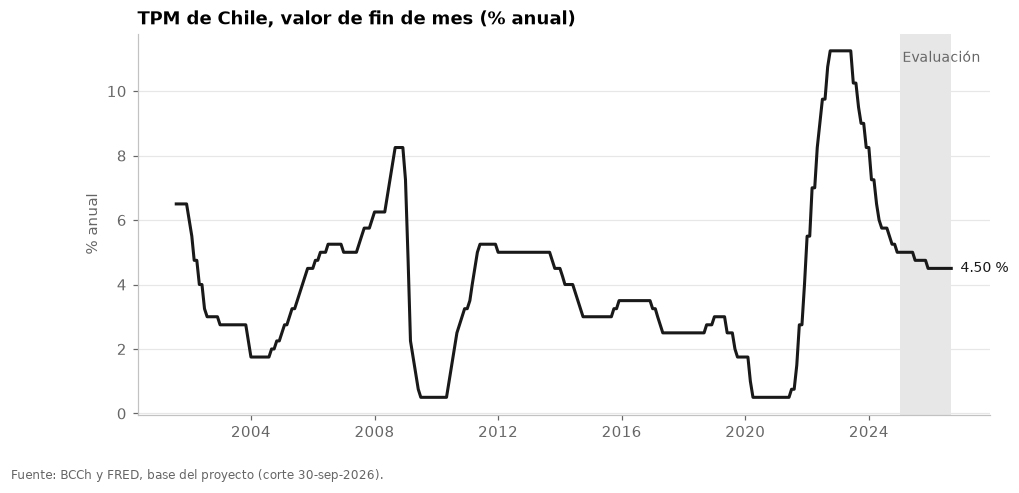

In [60]:
fig, ax = plt.subplots()
ax.axvspan(pd.Timestamp("2025-01-01"), tpm.index.max(), color="#e7e7e7", lw=0)
ax.text(pd.Timestamp("2025-02-01"), tpm.max(), "Evaluación", color=TINTA_SECUNDARIA, fontsize=9, va="top")
ax.plot(tpm.index, tpm, color=COLORES["TPM efectiva"])
ax.annotate(f"{tpm.iloc[-1]:.2f} %", (tpm.index[-1], tpm.iloc[-1]), xytext=(6, 0),
            textcoords="offset points", va="center", fontsize=9, color=TINTA)
ax.set_title("TPM de Chile, valor de fin de mes (% anual)")
ax.set_ylabel("% anual")
nota_fuente(fig)
plt.show()

### 3.2 ¿Hace falta un componente estacional?

Si la TPM diferenciada tuviera un patrón que se repite cada 12 meses, convendría un SARIMA. Lo revisamos con la autocorrelación en el rezago 12.

In [40]:
print(f"Autocorrelación en el rezago 12: {arima.autocorrelacion_estacional(entrenamiento):.2f}")

Autocorrelación en el rezago 12: 0.01


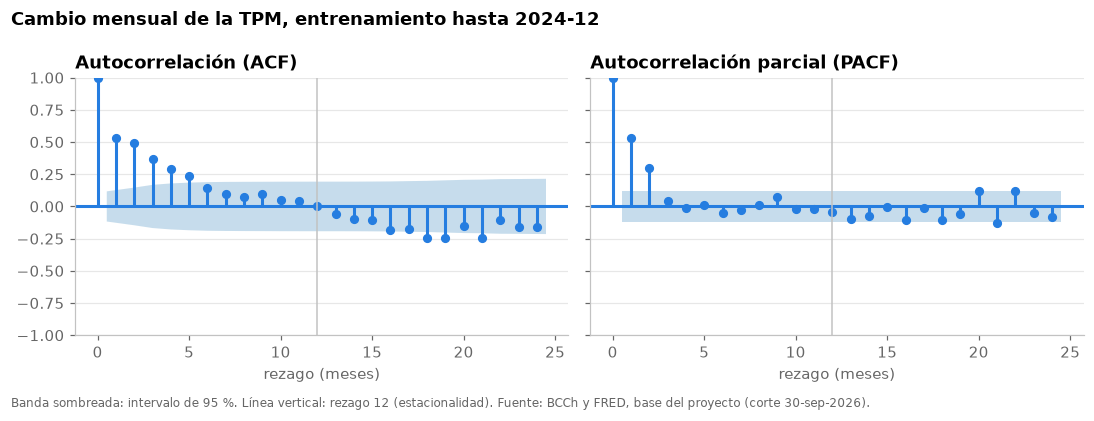

In [61]:
cambios = entrenamiento.diff().dropna()
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
plot_acf(cambios, lags=24, ax=ejes[0], color=COLORES["Regla de Taylor"],
         vlines_kwargs={"colors": COLORES["Regla de Taylor"]})
plot_pacf(cambios, lags=24, ax=ejes[1], method="ywm", color=COLORES["Regla de Taylor"],
          vlines_kwargs={"colors": COLORES["Regla de Taylor"]})
ejes[0].set_title("Autocorrelación (ACF)")
ejes[1].set_title("Autocorrelación parcial (PACF)")
for eje in ejes:
    eje.set_xlabel("rezago (meses)")
    eje.axvline(12, color="#c2c2c2", lw=1)
fig.suptitle("Cambio mensual de la TPM, entrenamiento hasta 2024-12", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
nota_fuente(fig, "Banda sombreada: intervalo de 95 %. Línea vertical: rezago 12 (estacionalidad). " + FUENTE)
plt.show()

Es prácticamente cero: el Consejo del BCCh fija la TPM en reuniones a lo largo del año, sin estacionalidad. Se usa ARIMA y no SARIMA.

### 3.3 Selección del orden por criterio de información

Como en la clase de *Árboles de decisión y Random Forest* (camino econométrico), el número de rezagos se decide **antes** de pronosticar, con un criterio de información: el **AIC** premia el buen ajuste y castiga cada parámetro adicional. Probamos $p$ y $q$ entre 0 y 3.

In [41]:
orden, tabla_aic = arima.seleccionar_orden(entrenamiento)
print(f"Orden elegido: ARIMA{orden}")
tabla_aic.head()

Orden elegido: ARIMA(2, 1, 0)


,p,d,q,AIC,BIC
0,2,1,0,141.328,152.232
1,3,1,0,142.741,157.280
2,1,1,2,142.747,157.286
3,2,1,1,142.793,157.332
4,1,1,1,144.374,155.278


### 3.4 Estimación y diagnóstico de residuos

Si el modelo captura bien la dinámica, sus residuos no deberían tener autocorrelación. Lo verificamos con la prueba de Ljung-Box (hipótesis nula: residuos sin autocorrelación).

In [42]:
ajuste_arima = arima.ajustar(entrenamiento, orden)
print(f"Ljung-Box (12 rezagos): p = {arima.p_valor_ljung_box(ajuste_arima):.3f}")
arima.tabla_coeficientes(ajuste_arima)

Ljung-Box (12 rezagos): p = 0.974


,coeficiente,error,p_valor
ar.L1,0.370,0.024,0.000
ar.L2,0.297,0.028,0.000
sigma2,0.095,0.003,0.000


**Lectura:** los dos coeficientes autorregresivos son positivos y significativos: cuando la TPM viene subiendo (o bajando), tiende a seguir haciéndolo. Es el *momentum* de los ciclos de política monetaria. Ljung-Box no rechaza la ausencia de autocorrelación: el modelo captura la dinámica.

## 4. Regla de Taylor

La regla describe cómo el Banco Central fija la tasa:

$$TPM_t = c + \rho \, TPM_{t-1} + \beta_\pi (EEE_t - 3) + \beta_y \, brecha_t + \beta_f \, FedFunds_t + \varepsilon_t$$

- $\rho$ mide la **inercia**: el BCCh ajusta la tasa de forma gradual.
- $\beta_\pi$ es la respuesta a la desviación de la **inflación esperada** respecto de la meta de 3 %.
- $\beta_y$ es la respuesta a la **brecha de actividad**.
- $\beta_f$ captura la influencia de la **tasa de EE.UU.**

Con inercia, el efecto de largo plazo de cada variable es $\beta / (1-\rho)$. Si la respuesta de largo plazo a la inflación es mayor que 1, se cumple el **principio de Taylor**: la tasa sube más que la inflación esperada, y así la tasa real aumenta.

### 4.1 Estimación por MCO con errores HAC

Como se vio en la clase de *Regresión lineal y pronóstico fuera de muestra*, en series de tiempo los errores suelen tener autocorrelación y heterocedasticidad: se viola el supuesto de no autocorrelación y los errores estándar de MCO quedan mal calculados. La corrección **Newey-West (HAC)** no cambia los coeficientes, pero corrige los errores estándar, los estadísticos t y los p-valores. Usamos 12 rezagos (un año en datos mensuales).

In [43]:
modelo_taylor = taylor.estimar(panel, "2024-12-01")
taylor.estadisticos(modelo_taylor)

inicio    2005-03-01 00:00:00
fin       2024-12-01 00:00:00
meses                     238
R2                      0.984
dtype: object

In [44]:
taylor.tabla_coeficientes(modelo_taylor)

,plazo,variable,coeficiente,error_hac,p_valor,significativo_5%
0,corto,Constante,0.249,0.052,0.000,True
1,corto,"TPM rezagada (ρ, inercia)",0.908,0.028,0.000,True
2,corto,Brecha de inflación esperada,0.313,0.054,0.000,True
3,corto,Brecha de actividad,0.029,0.015,0.059,False
4,corto,Fed Funds,0.031,0.031,0.313,False
5,largo,Brecha de inflación esperada,3.402,0.570,0.000,True
6,largo,Brecha de actividad,0.317,0.145,0.029,True
7,largo,Fed Funds,0.341,0.250,0.172,False


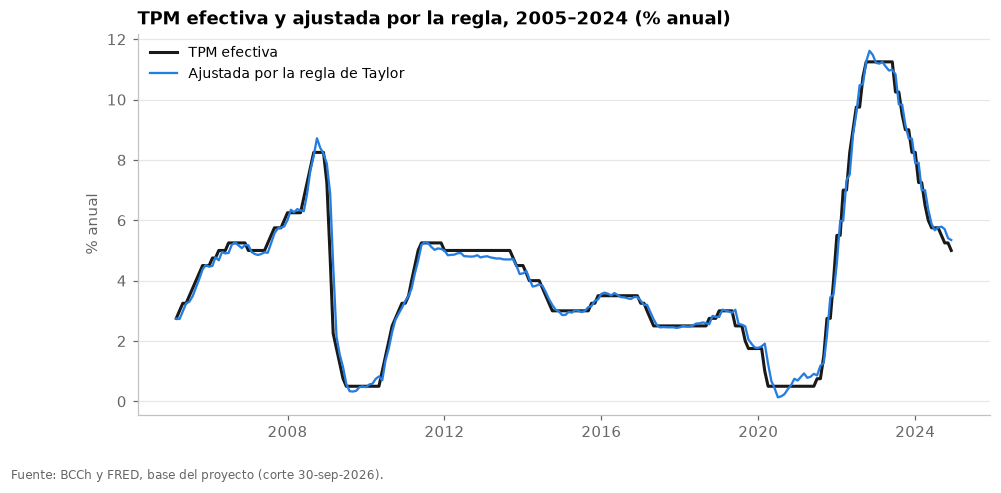

In [62]:
ajuste = taylor.ajustados(modelo_taylor)
fig, ax = plt.subplots()
ax.plot(ajuste.index, ajuste["tpm_efectiva"], color=COLORES["TPM efectiva"], label="TPM efectiva")
ax.plot(ajuste.index, ajuste["tpm_ajustada"], color=COLORES["Regla de Taylor"], lw=1.5,
        label="Ajustada por la regla de Taylor")
ax.set_title("TPM efectiva y ajustada por la regla, 2005–2024 (% anual)")
ax.set_ylabel("% anual")
ax.legend(loc="upper left")
nota_fuente(fig)
plt.show()

**Lectura:**

- **Inercia:** $\rho \approx 0,91$, el coeficiente más grande y muy significativo. El BCCh se mueve de a poco, en línea con Apablaza y Ortiz (2024).
- **Inflación esperada:** respuesta de largo plazo cercana a 3,4, mayor que 1. **Se cumple el principio de Taylor.**
- **Actividad:** efecto positivo, significativo al 5 % en el largo plazo y al 10 % en el corto plazo.
- **Fed Funds:** no es significativa una vez que se controla por expectativas y actividad. Es coherente con un tipo de cambio flexible, que le da autonomía a la política monetaria.

### 4.2 ¿Por qué hacía falta HAC? Durbin-Watson

El estadístico de Durbin-Watson resume la autocorrelación de primer orden de los residuos: $DW \approx 2(1-\hat{\rho}_{resid})$. Cerca de 2 no hay autocorrelación; bajo 1,5 hay autocorrelación positiva.

In [45]:
print(f"Durbin-Watson: {durbin_watson(modelo_taylor.resid):.2f}")

Durbin-Watson: 1.28


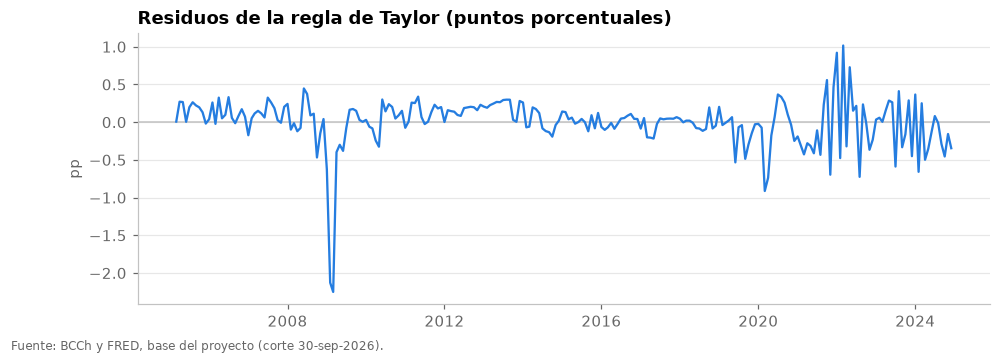

In [63]:
residuos = modelo_taylor.resid
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.axhline(0, color="#c2c2c2", lw=1)
ax.plot(residuos.index, residuos, color=COLORES["Regla de Taylor"], lw=1.5)
ax.set_title("Residuos de la regla de Taylor (puntos porcentuales)")
ax.set_ylabel("pp")
nota_fuente(fig)
plt.show()

El valor está bajo 1,5: los residuos tienen autocorrelación positiva. Sin la corrección HAC, los p-valores de la tabla anterior estarían inflados. El $R^2$ cercano a 0,98 tampoco dice mucho sobre la capacidad de pronóstico: refleja sobre todo la inercia. Por eso lo que importa es la evaluación fuera de muestra de la sección 5.

### 4.3 Estabilidad de los coeficientes

Si la regla describe bien al BCCh, los coeficientes no deberían cambiar mucho al agregar los datos de 2025 y 2026.

In [46]:
pd.concat({"hasta 2024-12": taylor.coeficientes(modelo_taylor),
           "muestra completa": taylor.coeficientes(taylor.estimar(panel))}, axis=1)

,hasta 2024-12,muestra completa
constante,0.249,0.244
tpm_lag1,0.908,0.910
brecha_inflacion_esp,0.313,0.308
brecha_actividad,0.029,0.028
fed_funds,0.031,0.027


Los coeficientes son prácticamente iguales: la regla es estable. Frente a Caputo y Herrera (2013), con respuestas de largo plazo de 1,174 (inflación esperada), 0,656 (brecha) y 1,2 (Fed Funds), los signos coinciden; la respuesta a la inflación esperada es mayor y a la Fed, menor.

## 5. Evaluación fuera de muestra

Un $R^2$ alto dentro de muestra no garantiza un buen pronóstico: el modelo puede estar memorizando el pasado. La pregunta correcta es cuánto se equivoca **fuera de muestra**, con datos que no vio al estimarse.

**Diseño:** ventana **recursiva** (o expansiva). En cada fecha de pronóstico se reestima el modelo con toda la historia disponible hasta ese momento, y nunca con datos posteriores.

**Métricas** (en puntos porcentuales de TPM):

$$RMSE = \sqrt{\frac{1}{T}\sum (y_t - \hat{y}_t)^2} \qquad MAE = \frac{1}{T}\sum |y_t - \hat{y}_t| \qquad R^2_{oos} = 1 - \frac{MSPE_{modelo}}{MSPE_{benchmark}}$$

$R^2_{oos} > 0$ significa que el modelo reduce el error cuadrático del benchmark (Campbell y Thompson, 2008); $R^2_{oos} < 0$, que es peor que el benchmark.

### 5.1 Comparación principal a 6, 12 y 24 meses

Nueve cortes, en septiembre de cada año entre 2016 y 2024. En cada corte:

- La **regla de Taylor** se estima con datos hasta el corte, parte de la TPM del corte y usa los determinantes conocidos al cierre del corte. Los determinantes se mantienen fijos durante el horizonte.
- El **ARIMA** usa un orden elegido una sola vez con datos hasta el primer corte (2016-09), y reestima sus coeficientes en cada corte.
- La **caminata aleatoria** mantiene la TPM del corte.

In [47]:
detalle_cortes, metricas_cortes, orden_cortes = evaluacion.evaluar_cortes(panel)
print(f"ARIMA usado en esta evaluación: ARIMA{orden_cortes}\n")

metricas_cortes.pivot(index="horizonte", columns="modelo", values="RMSE")

ARIMA usado en esta evaluación: ARIMA(2, 1, 2)



modelo,ARIMA,Caminata aleatoria,Regla de Taylor
horizonte,,,
6,1.427,2.036,1.483
12,2.967,3.467,2.945
24,4.967,5.008,5.738


In [48]:
# R² fuera de muestra frente a la caminata aleatoria
metricas_cortes.pivot(index="horizonte", columns="modelo", values="R2_OOS")

modelo,ARIMA,Caminata aleatoria,Regla de Taylor
horizonte,,,
6,0.509,0.000,0.470
12,0.267,0.000,0.278
24,0.016,0.000,-0.313


In [ ]:
horizontes = sorted(detalle_cortes["horizonte"].unique())
historia = tpm.loc["2016-09-01":]
fig, ejes = plt.subplots(len(horizontes), 1, figsize=(10, 8.5), sharex=True, sharey=True)
for eje, h in zip(ejes, horizontes):
    datos = detalle_cortes[detalle_cortes["horizonte"] == h]
    eje.plot(historia.index, historia, color=COLORES["TPM efectiva"], lw=1.5, label="TPM efectiva")
    for modelo in [BENCHMARK, "ARIMA", "Regla de Taylor"]:
        eje.scatter(datos["mes_objetivo"], datos[modelo], s=55, color=COLORES[modelo],
                    edgecolor="white", linewidth=1.5, zorder=3, label=modelo)
    eje.set_title(f"Pronóstico a {h} meses", fontsize=11)
    eje.set_ylabel("% anual")
ejes[0].legend(loc="upper left", ncol=4)
fig.suptitle("Pronósticos fuera de muestra frente a la TPM efectiva (cortes sep-2016 a sep-2024)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
nota_fuente(fig, "Cada punto es el pronóstico hecho en un corte para el mes en que se ubica. " + FUENTE)
plt.show()

In [ ]:
modelos = [BENCHMARK, "Regla de Taylor", "ARIMA"]
tabla = metricas_cortes.pivot(index="horizonte", columns="modelo", values="RMSE")[modelos]
x = np.arange(len(tabla))
ancho = 0.26
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, modelo in enumerate(modelos):
    ax.bar(x + (i - 1) * ancho, tabla[modelo], width=ancho * 0.9, color=COLORES[modelo], label=modelo)
ax.set_xticks(x, [f"{h} meses" for h in tabla.index])
ax.set_title("Error de pronóstico fuera de muestra (RMSE, pp; menor es mejor)")
ax.set_ylabel("RMSE (pp)")
ax.legend(loc="upper left")
nota_fuente(fig, "Cortes sep-2016 a sep-2024. " + FUENTE)
plt.show()

**Lectura:**

- **A 6 meses**, el ARIMA tiene el menor error y la regla de Taylor también supera a la caminata aleatoria.
- **A 12 meses**, la regla de Taylor tiene el menor error, levemente bajo el ARIMA. Ambos superan al benchmark.
- **A 24 meses**, ningún modelo supera con claridad a la caminata aleatoria: la regla queda peor, porque sus determinantes se mantienen fijos durante dos años.

### 5.2 Doble $R^2_{oos}$: la regla frente al ARIMA

Como en la clase de *Benchmarks econométricos*, además de compararnos con el benchmark ingenuo nos comparamos con el univariado: ¿la regla aporta algo que no esté ya en la historia de la TPM?

In [49]:
tabla_metricas(detalle_cortes, ["Regla de Taylor"], benchmark="ARIMA")[["horizonte", "RMSE", "R2_OOS"]]

,horizonte,RMSE,R2_OOS
0,6,1.483,-0.080
1,12,2.945,0.015
2,24,5.738,-0.335


Frente al ARIMA, la regla solo gana por muy poco a 12 meses y pierde a 6 y 24. Las variables económicas aportan sobre todo para **interpretar** y construir escenarios, más que para mejorar la precisión.

### 5.3 ¿La mejora es significativa? Test de Clark y West (2007)

Un modelo puede ganar por azar en un período particular. El test de Clark y West compara un modelo grande con uno pequeño anidado en él y corrige la desventaja del modelo grande, que estima parámetros adicionales. Es el mismo test usado en la clase de *Regularización*.

Hipótesis nula: el modelo grande no pronostica mejor que el benchmark. $p < 0,05$: el modelo grande es significativamente mejor.

In [50]:
def clark_west(real, benchmark, modelo, maxlags=12):
    # Clark y West (2007): diferencia de errores ajustada, con errores HAC
    ajustada = (real - benchmark) ** 2 - ((real - modelo) ** 2 - (benchmark - modelo) ** 2)
    regresion = sm.OLS(ajustada, np.ones(len(ajustada))).fit(
        cov_type="HAC", cov_kwds={"maxlags": maxlags})
    estadistico = regresion.tvalues[0]
    return pd.Series({"estadistico_CW": estadistico, "p_valor": 1 - norm.cdf(estadistico)})


# Regla de Taylor frente a la caminata aleatoria, por horizonte (pocos cortes: rezagos HAC bajos)
pd.DataFrame({h: clark_west(g["tpm_real"].values, g[BENCHMARK].values,
                            g["Regla de Taylor"].values, maxlags=2)
              for h, g in detalle_cortes.groupby("horizonte")}).T

,estadistico_CW,p_valor
6,1.491,0.068
12,1.333,0.091
24,0.373,0.354


**Lectura:** a 6 y 12 meses la mejora de la regla sobre la caminata aleatoria es significativa solo al 10 %, y a 24 meses no lo es. Con apenas 9 cortes por horizonte, el test tiene poco poder: la evidencia orienta, pero no es concluyente.

### 5.4 Pronóstico a un mes y validación temporal

Ahora evaluamos la regla un paso adelante ($h = 1$), usando cada mes la TPM observada del mes anterior.

**a) Período reciente:** coeficientes estimados hasta diciembre de 2024 y 21 pronósticos entre enero de 2025 y septiembre de 2026.

In [51]:
detalle_un_paso, metricas_un_paso = evaluacion.evaluar_un_paso(panel)
metricas_un_paso

,grupo,modelo,n,MAE,RMSE,R2_OOS
0,total,Regla de Taylor,21,0.109,0.136,-2.093
1,total,Caminata aleatoria,21,0.024,0.077,0.000


In [52]:
clark_west(detalle_un_paso["tpm_real"].values, detalle_un_paso[BENCHMARK].values,
           detalle_un_paso["Regla de Taylor"].values)

estadistico_CW   -1.922
p_valor           0.973
dtype: float64

A un mes, en un período de recortes graduales, la caminata aleatoria es muy difícil de superar: la TPM casi no cambia de un mes a otro.

**b) Validación temporal:** la misma evaluación con cuatro cortes (diciembre de 2021 a 2024), reestimando la regla en cada corte y evaluando los 12 meses siguientes.

In [53]:
detalle_validacion, metricas_validacion = evaluacion.validacion_temporal(panel)
metricas_validacion.pivot(index="corte", columns="modelo", values="RMSE")

modelo,Caminata aleatoria,Regla de Taylor
corte,,
2021-12-01,0.839,0.575
2022-12-01,0.445,0.319
2023-12-01,0.415,0.378
2024-12-01,0.102,0.161


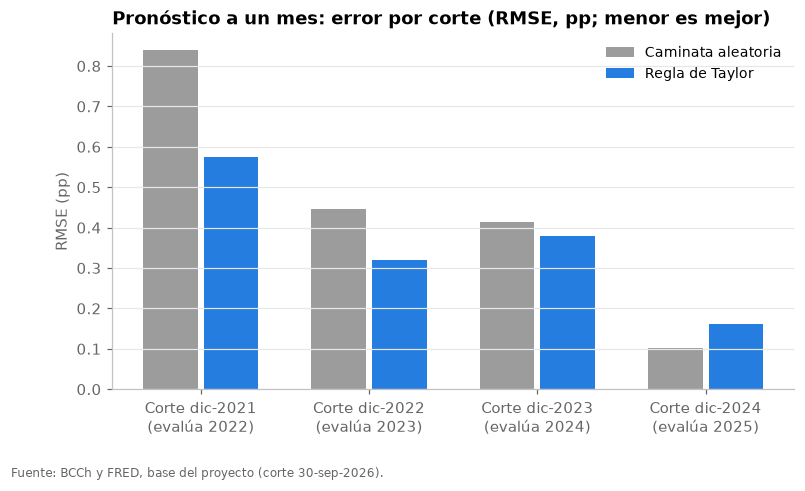

In [64]:
modelos = [BENCHMARK, "Regla de Taylor"]
tabla = metricas_validacion.pivot(index="corte", columns="modelo", values="RMSE")[modelos]
x = np.arange(len(tabla))
ancho = 0.36
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, modelo in enumerate(modelos):
    ax.bar(x + (i - 0.5) * ancho, tabla[modelo], width=ancho * 0.9, color=COLORES[modelo], label=modelo)
ax.set_xticks(x, [f"Corte dic-{c.year}\n(evalúa {c.year + 1})" for c in tabla.index])
ax.set_title("Pronóstico a un mes: error por corte (RMSE, pp; menor es mejor)")
ax.set_ylabel("RMSE (pp)")
ax.legend(loc="upper right")
nota_fuente(fig, y=-0.08)
plt.show()

In [54]:
# Test con los 48 pronósticos de los cuatro cortes juntos
clark_west(detalle_validacion["tpm_real"].values, detalle_validacion[BENCHMARK].values,
           detalle_validacion["Regla de Taylor"].values)

estadistico_CW   1.929
p_valor          0.027
dtype: float64

**Lectura:** la regla le gana a la caminata aleatoria en los cortes de 2021, 2022 y 2023, cuando la TPM se movía con fuerza, y pierde en 2024, con la tasa casi estable. Con los 48 pronósticos juntos, la mejora es **significativa al 5 %**: la regla aporta cuando la política monetaria está en movimiento.

### 5.5 Robustez del ARIMA: $d = 1$ frente a $d = 0$

Evaluamos el ARIMA en el período reciente (enero de 2025 a septiembre de 2026) a 1, 6 y 12 meses. Los órdenes se eligen con datos hasta enero de 2024, el primer origen de los pronósticos a 12 meses, para que la evaluación no influya en la elección.

In [55]:
detalle_arima, metricas_arima, ordenes = evaluacion.evaluar_arima_reciente()
print("Órdenes elegidos:", ", ".join(ordenes))
metricas_arima.pivot(index="horizonte", columns="modelo", values="RMSE")

Órdenes elegidos: ARIMA(2, 1, 0), ARIMA(2, 0, 1)


modelo,"ARIMA(2, 0, 1)","ARIMA(2, 1, 0)",Caminata aleatoria
horizonte,,,
1,0.093,0.089,0.077
6,0.341,0.315,0.336
12,1.090,0.789,1.185


El ARIMA con $d = 1$ supera a la caminata aleatoria a 6 y 12 meses, y en todos los horizontes se equivoca menos que el ARIMA con $d = 0$.

## 6. Proyección a 24 meses y escenarios de riesgo

### 6.1 Punto de partida

Para proyectar desde septiembre de 2026 se usa todo lo que se sabía **al cierre de septiembre**, con los mismos rezagos de publicación del panel: EEE de septiembre, Fed Funds de septiembre, brecha calculada con el Imacec de julio y TPM de septiembre.

In [56]:
punto = proyeccion.punto_partida()
punto

tpm_lag1                4.500
brecha_inflacion_esp    0.300
brecha_actividad       -1.760
fed_funds               3.750
Name: 2026-10-01 00:00:00, dtype: float64

### 6.2 Proyecciones

- **Regla de Taylor**, estimada con toda la muestra. La proyección es recursiva: cada TPM proyectada es el rezago del mes siguiente.
- **ARIMA**, con su intervalo de confianza de 80 %. El límite inferior no baja de 0,5 %, el mínimo histórico.
- **Caminata aleatoria**, como benchmark.

Escenarios de la regla. Los tamaños de los shocks son ilustrativos: muestran hacia dónde y cuánto se movería la TPM, no son pronósticos de esas variables.

| Escenario | Supuesto |
|---|---|
| Base | Determinantes constantes en su último valor conocido |
| Convergencia | Expectativas a la meta y brecha cerrada, de forma lineal en 12 meses |
| Riesgo al alza | Expectativas +1 pp y Fed Funds +0,5 pp |
| Riesgo a la baja | Brecha −2 pp, expectativas −0,5 pp y Fed Funds −1 pp |

In [57]:
proyecciones = proyeccion.proyectar()
proyeccion.resumen(proyecciones)

horizonte                              6     12    24
modelo             escenario                         
Regla de Taylor    Base             4.432 4.393 4.358
                   Convergencia     4.366 4.186 3.965
                   Riesgo al alza   5.976 6.815 7.564
                   Riesgo a la baja 3.294 2.608 1.996
ARIMA              ARIMA(2, 1, 0)   4.500 4.500 4.500
Caminata aleatoria Sin cambio       4.500 4.500 4.500

In [58]:
proyeccion.intervalo_arima(proyecciones)

,mes,tpm,li,ls
horizonte,,,,
6,2027-03-01,4.500,2.641,6.359
12,2027-09-01,4.500,1.228,7.772
24,2028-09-01,4.500,0.500,9.722


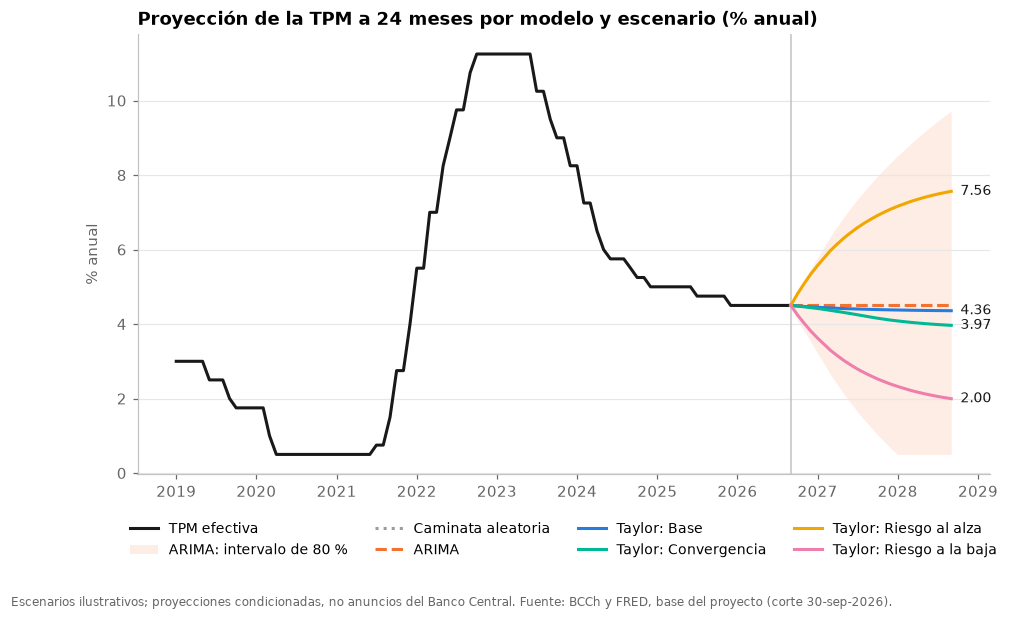

In [65]:
historia = tpm.loc["2019-01-01":]
ultimo_mes, ultima_tpm = historia.index[-1], historia.iloc[-1]


def desde_ultimo_dato(datos, columna="tpm"):
    """Antepone el último dato observado para que la proyección parta desde la TPM efectiva."""
    return [ultimo_mes] + list(datos["mes"]), [ultima_tpm] + list(datos[columna])


fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(historia.index, historia, color=COLORES["TPM efectiva"], label="TPM efectiva")
ax.axvline(ultimo_mes, color="#c2c2c2", lw=1)

datos_arima = proyecciones[proyecciones["modelo"] == "ARIMA"]
ax.fill_between(*desde_ultimo_dato(datos_arima, "li"), desde_ultimo_dato(datos_arima, "ls")[1],
                color=COLORES["ARIMA"], alpha=0.12, lw=0, label="ARIMA: intervalo de 80 %")
datos_caminata = proyecciones[proyecciones["modelo"] == BENCHMARK]
ax.plot(*desde_ultimo_dato(datos_caminata), color=COLORES[BENCHMARK], ls=":", label=BENCHMARK)
ax.plot(*desde_ultimo_dato(datos_arima), color=COLORES["ARIMA"], ls="--", label="ARIMA")

datos_taylor = proyecciones[proyecciones["modelo"] == "Regla de Taylor"]
for escenario, datos in datos_taylor.groupby("escenario", sort=False):
    color = COLORES["Regla de Taylor"] if escenario == "Base" else COLORES[escenario]
    ax.plot(*desde_ultimo_dato(datos), color=color, label=f"Taylor: {escenario}")
    ax.annotate(f"{datos['tpm'].iloc[-1]:.2f}", (datos["mes"].iloc[-1], datos["tpm"].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=TINTA)

ax.set_title("Proyección de la TPM a 24 meses por modelo y escenario (% anual)")
ax.set_ylabel("% anual")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4)
nota_fuente(fig, "Escenarios ilustrativos; proyecciones condicionadas, no anuncios del Banco Central. "
            + FUENTE, y=-0.12)
plt.show()

### 6.3 ¿Hacia dónde converge la regla?

Si los determinantes se quedan constantes, la regla converge a un nivel de largo plazo:

$$TPM^{*} = \frac{c + \beta_\pi (EEE - 3) + \beta_y \, brecha + \beta_f \, FedFunds}{1 - \rho}$$

Este nivel ayuda a interpretar el escenario base: dice cuál sería la TPM "de equilibrio" según la regla, con la información de hoy.

In [59]:
coef = taylor.coeficientes(taylor.estimar(panel))
nivel_largo_plazo = ((coef["constante"] + (coef[taylor.DETERMINANTES] * punto[taylor.DETERMINANTES]).sum())
                     / (1 - coef["tpm_lag1"]))
print(f"Nivel de largo plazo de la regla (escenario base): {nivel_largo_plazo:.2f} %")

Nivel de largo plazo de la regla (escenario base): 4.34 %


**Lectura económica:**

- **Escenario base:** la regla converge a alrededor de 4,3 %, apenas bajo la TPM actual de 4,5 %. A septiembre de 2028 proyecta 4,36 %: una TPM prácticamente estable.
- **ARIMA y caminata aleatoria:** proyectan 4,50 %. La TPM no se ha movido en los últimos meses y el ARIMA no detecta una tendencia que extrapolar.
- **Convergencia:** si las expectativas vuelven a la meta y la brecha se cierra, la TPM baja a 3,97 %. Pesa más el cierre de la brecha de expectativas (+0,3 pp) que el de la brecha de actividad (−1,76 %), porque la regla responde mucho más a la inflación esperada.
- **Riesgo al alza:** un desanclaje de expectativas de 1 pp, junto con una Fed más restrictiva, lleva la TPM a 7,56 %. Es el riesgo principal, por la fuerte respuesta de largo plazo a la inflación esperada (≈ 3,4).
- **Riesgo a la baja:** una recesión global la llevaría a cerca de 2,0 %.
- **Incertidumbre:** el intervalo de 80 % del ARIMA a 24 meses va de 0,5 % a 9,7 %: a dos años la incertidumbre es muy alta.

Son proyecciones condicionadas de los modelos, no anuncios del Banco Central.

## 7. Conclusiones y limitaciones

**Respuesta a la pregunta:** la lectura conjunta de los modelos apunta a una **TPM relativamente estable, entre 4,3 % y 4,5 %**, en los próximos dos años. El principal riesgo al alza es un desanclaje de las expectativas de inflación; a la baja, una recesión global.

**Sobre los modelos:**

- La regla de Taylor **explica bien** el comportamiento del BCCh: inercia alta, principio de Taylor y coeficientes estables.
- Como herramienta de **pronóstico**, el ARIMA es el más preciso a 6 meses y la regla a 12 meses, pero las diferencias son pequeñas. A 24 meses ningún modelo supera con claridad a la caminata aleatoria.
- La regla aporta más cuando la política monetaria está en movimiento (validación temporal significativa al 5 %).

**Limitaciones:**

- Pocos cortes de evaluación (9 por horizonte) y ventanas que se superponen: los tests tienen poco poder.
- La regla mantiene sus determinantes fijos durante el horizonte; un modelo que también los pronostique podría mejorar a 24 meses.
- La brecha en tiempo real usa el Imacec en su versión actual, no la publicada en cada fecha: las revisiones posteriores no se capturan.
- La especificación de la regla se eligió conociendo toda la muestra, lo que puede favorecerla levemente dentro de muestra.
- El período 2025–2026 cubre un solo ciclo de política (recortes graduales).